### Social Graph Construction using Voter Fraud 2020 Dataset

In [1]:
import pandas as pd
import torch
import networkx as nx
import matplotlib.pyplot as plt

##### Load and inspect data

In [2]:
users = pd.read_csv("data/users.csv", dtype={"user_id": str})
retweets = pd.read_csv("data/retweets-2020-12.csv", nrows=50,
                       dtype={"user_id": str, "retweeted_id": str}) # load only 50 rows for now

In [3]:
users

,user_id,user_community,user_active_status,closeness_centrality_detractor_cluster,closeness_centrality_promoter_cluster,retweet_count_by_community_0,quote_count_by_community_0,retweet_count_by_community_1,quote_count_by_community_1,retweet_count_by_community_2,quote_count_by_community_2,retweet_count_by_community_3,quote_count_by_community_3,retweet_count_by_community_4,quote_count_by_community_4,retweet_count_by_suspended_users,quote_count_by_suspended_users
0,6590,0.0,suspended,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0
1,10597,NaN,deleted,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0
2,16943,NaN,suspended,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0
3,29803,NaN,suspended,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0
4,68093,0.0,suspended,0.076194,NaN,16,0,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2559013,899317849243693057,2.0,suspended,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0
2559014,1296302672077758464,2.0,suspended,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0
2559015,1403510982,1.0,deleted,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0
2559016,1331876413926936577,1.0,suspended,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0


In [4]:
retweets

,retweeted_id,user_id
0,1333536078385569804,47163171
1,1333558948272758785,15129460
2,1333564311701221384,1309469972184199169
3,1333556242984431616,28175561
4,1333556242984431616,1290184417420414977
5,1333408374764015619,829399083865432064
6,1333551286348902403,1325639331202158594
7,1333552672432119817,1885585776
8,1333564113151258627,2838446184
9,1333556301457215488,849797163098009601


**Creating a co-retweet graph.**
Since the `tweets` table does not indicate the author or the user ID who posted it, the graph will connect users based on the shared tweets that they retweeted/interacted with.

In [5]:
retweeters = (
    retweets.groupby("retweeted_id")["user_id"]
    .apply(list)
    .reset_index()
)
retweeters.columns = ["tweet_id", "retweeters"]

In [6]:
retweeters

,tweet_id,retweeters
0,1333048166397202432,[1195187635687493637]
1,1333085430829502464,[186150082]
2,1333191356190175232,[301081721]
3,1333243285389914112,[1261468819]
4,1333397676667269121,[53818115]
5,1333408374764015619,[829399083865432064]
6,1333430836859953157,[485179361]
7,1333440821937508356,[898771784]
8,1333455757153484802,[1280913116612538371]
9,1333463037601169408,"[1019062960147386368, 3014215457]"


In [7]:
nodes = users[["user_id", "user_community"]].dropna(
    subset=["user_community"]
).copy()

In [8]:
valid_users = set(nodes["user_id"])

In [9]:
# Build the nodes
G = nx.Graph() # undirected

for _, row in nodes.iterrows():
    G.add_node(
        row["user_id"],
        community = row["user_community"]
    )

In [10]:
# Build the edges
from itertools import combinations
for _, row in retweeters.iterrows():
    retweeters = [u for u in row["retweeters"] if u in valid_users]
    for user_a, user_b in combinations(retweeters, 2):
        if G.has_edge(user_a, user_b):
            G[user_a][user_b]["weight"] += 1
        else:
            G.add_edge(user_a, user_b, weight=1)

In [11]:
print(f"Nodes: {G.number_of_nodes()}")
print(f"Edges: {G.number_of_edges()}")

Nodes: 1697944
Edges: 19


In [12]:
# Remove nodes without edges
isolated = list(nx.isolates(G))
G.remove_nodes_from(isolated)

print(f"Nodes with edges: {G.number_of_nodes()}")

Nodes with edges: 11


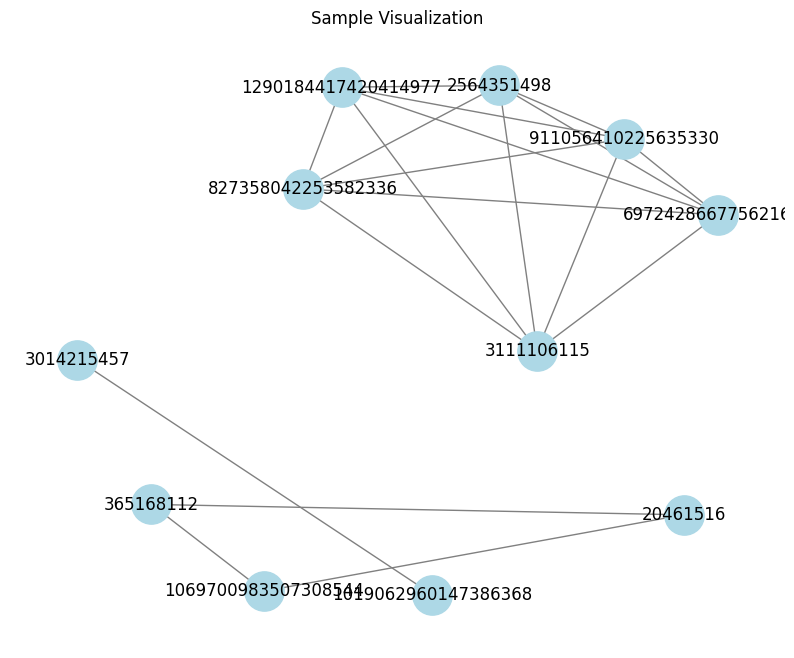

In [14]:
pos = nx.spring_layout(G, seed=42, k=2) # fixed seed

# Draw a graph
fig, ax = plt.subplots(figsize=(10,8))
nx.draw_networkx(G, pos, with_labels=True, node_color='lightblue', edge_color='gray', node_size=800)
labels = {n: str(n)[:6] for n in G.nodes()}  # truncate long IDs

plt.title("Sample Visualization")
plt.axis('off')
plt.show()